Name: Keerthi N

Registration No: 2411021240024

University: Alliance University

Subject: Deep Learning

Topic: Handwritten Digit Classification Using CNN

# Project 11: Handwritten Digit Classification Using CNN

## Objective

The objective of this project is to build a Convolutional Neural Network (CNN) to classify handwritten digits using the MNIST dataset.

The project includes loading and preprocessing the dataset, building and training a CNN model, and evaluating the model using accuracy, confusion matrix, classification report, and sample predictions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## Task 1: Load the MNIST Dataset

The MNIST dataset contains 70,000 grayscale images of handwritten digits from 0 to 9.

It contains:
- 60,000 training images
- 10,000 testing images

Each image has a size of 28 × 28 pixels.

In [2]:
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


## Exploring the Dataset

The following images show examples from the MNIST dataset. Each image represents a handwritten digit between 0 and 9.

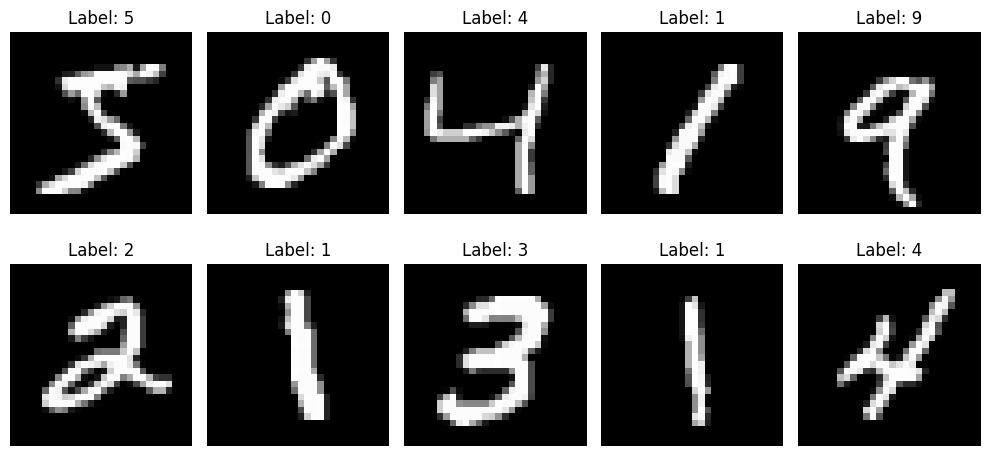

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

## Image Preprocessing

The pixel values of MNIST images range from 0 to 255.

To make training easier, the pixel values are normalized to a range between 0 and 1.

The images are also reshaped to include one channel because MNIST images are grayscale.

In [4]:
# Normalize pixel values
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)


## Task 2: Building the CNN Model

A Convolutional Neural Network is used because the input data consists of images.

The model contains convolutional layers for feature extraction, pooling layers for reducing the feature size, and dense layers for classification.

The final layer contains 10 neurons because there are 10 possible digit classes from 0 to 9.

In [5]:
model = models.Sequential([

    # First convolution block
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into one-dimensional vector
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(128, activation='relu'),

    # Dropout to reduce overfitting
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully.")

Model compiled successfully.


## Training the CNN Model

The CNN model is trained using the MNIST training dataset.

The model will learn the patterns present in handwritten digits and use these patterns to classify new images.

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.9206 - loss: 0.2602 - val_accuracy: 0.9845 - val_loss: 0.0585
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.9727 - loss: 0.0912 - val_accuracy: 0.9887 - val_loss: 0.0398
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 30ms/step - accuracy: 0.9797 - loss: 0.0668 - val_accuracy: 0.9908 - val_loss: 0.0366
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.9839 - loss: 0.0536 - val_accuracy: 0.9898 - val_loss: 0.0389
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 31ms/step - accuracy: 0.9861 - loss: 0.0452 - val_accuracy: 0.9907 - val_loss: 0.0359


## Training and Validation Accuracy

The following graph shows how the training and validation accuracy changed during training.

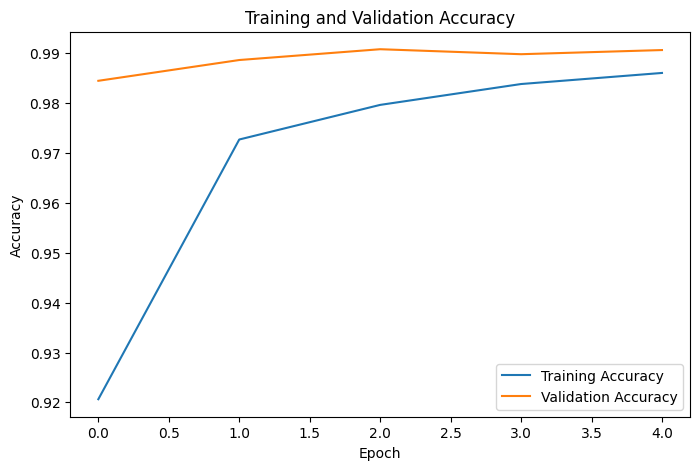

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')

plt.legend()
plt.show()

## Task 3: Model Evaluation

The trained CNN is evaluated using the MNIST test dataset.

Test accuracy is used to measure how well the model can classify previously unseen handwritten digit images.

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy Percentage:", test_accuracy * 100)

Test Loss: 0.029605813324451447
Test Accuracy: 0.9905999898910522
Test Accuracy Percentage: 99.05999898910522


In [10]:
y_pred_prob = model.predict(x_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Predictions generated successfully.")
print("First 20 predictions:", y_pred[:20])
print("Actual labels:", y_test[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Predictions generated successfully.
First 20 predictions: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
Actual labels: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]


## Confusion Matrix

A confusion matrix is used to understand the classification performance of the CNN for each digit.

The rows represent the actual classes and the columns represent the predicted classes.

A high value along the diagonal indicates correct predictions.

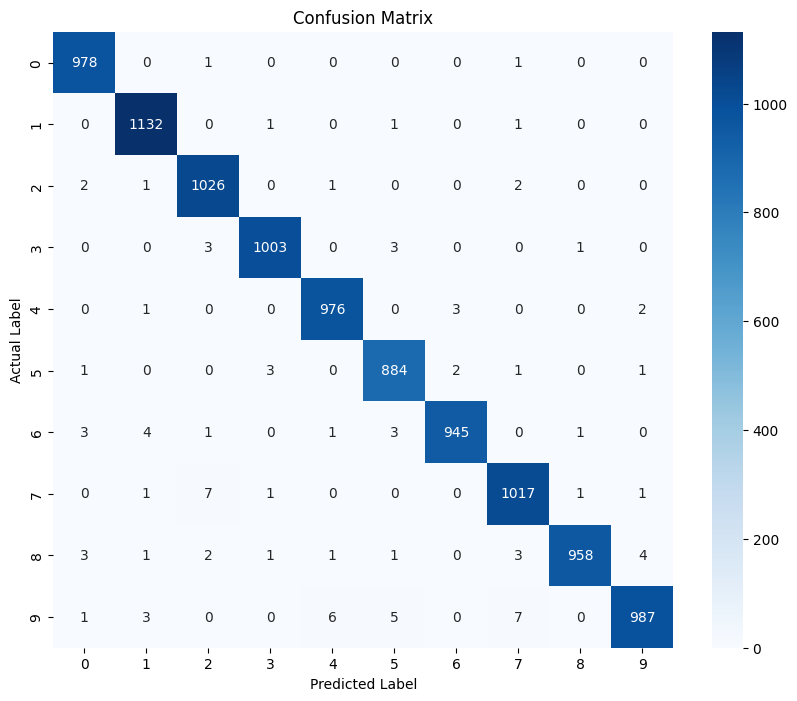

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.show()

## Classification Report

The classification report provides precision, recall, F1-score, and support for each digit class.

Precision shows how many predicted samples were actually correct.

Recall shows how many actual samples of a class were correctly identified.

F1-score combines precision and recall into a single value.

In [12]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[str(i) for i in range(10)]
    )
)

Classification Report:

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       1.00      0.98      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



## Sample Predictions

The following examples show handwritten digit images from the test dataset along with the actual and predicted labels.

This helps visually verify whether the CNN is making correct predictions.

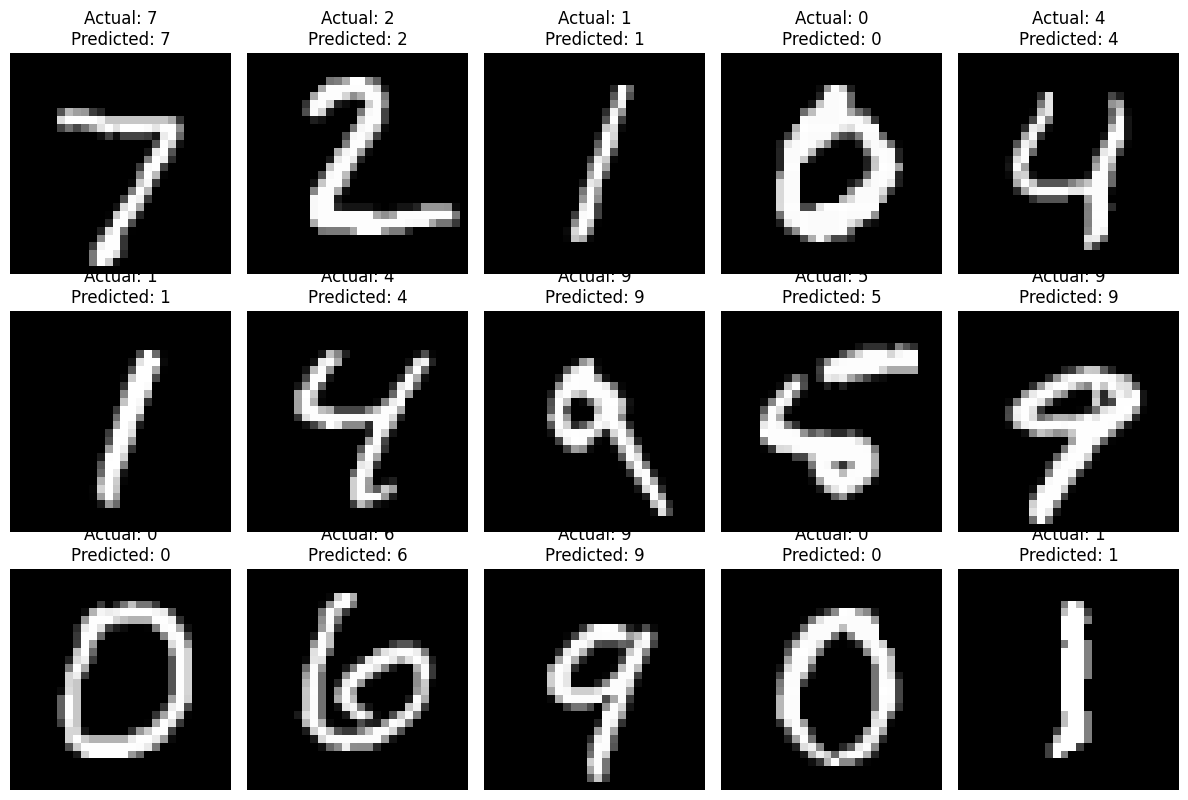

In [13]:
plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_test[i].squeeze(), cmap='gray')

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

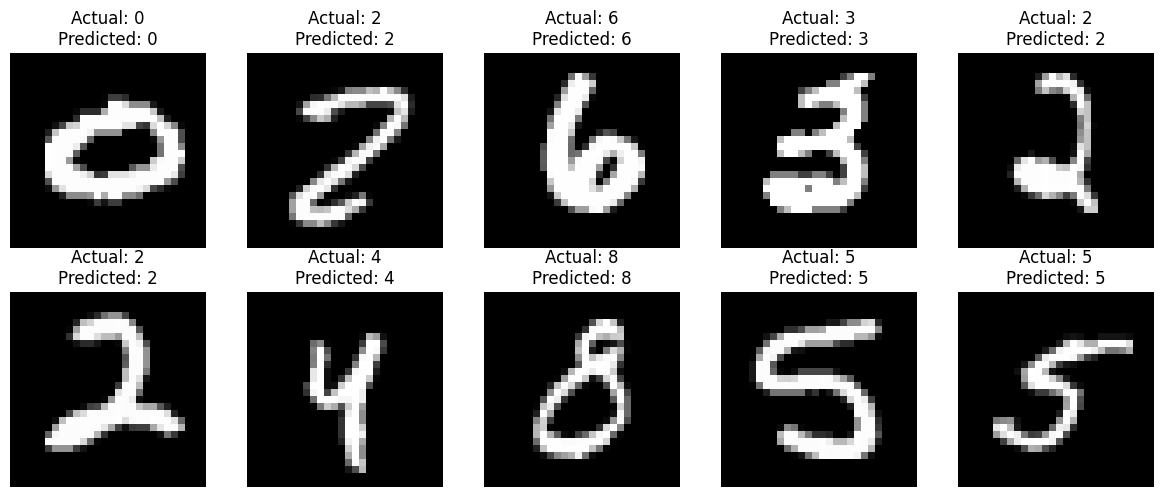

In [14]:
random_indices = np.random.choice(len(x_test), 10, replace=False)

plt.figure(figsize=(12, 5))

for i, index in enumerate(random_indices):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[index].squeeze(), cmap='gray')

    plt.title(
        f"Actual: {y_test[index]}\nPredicted: {y_pred[index]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

## Conclusion

In this project, a Convolutional Neural Network was developed to classify handwritten digits using the MNIST dataset.

The images were normalized and reshaped before training. A CNN model containing convolutional, pooling, flatten, dense, and dropout layers was built and trained.

The model was evaluated using test accuracy, a confusion matrix, classification report, and sample predictions.

The results show that CNNs can effectively learn image features and accurately classify handwritten digits from 0 to 9.